# UKHSA Disease Tracking Dashboard

This dashboard presents testing positivity rates for three respiratory diseases in England: **Adenovirus**, **Influenza**, and **RSV**.

The data is retrieved from the [UK Health Security Agency (UKHSA) API](https://ukhsa-dashboard.data.gov.uk/) and displayed via interactive charts. Users can explore weekly and monthly trends, and refresh the data live.

### Why these diseases?

Adenovirus, Influenza, and RSV are respiratory diseases that circulate together during the winter months in the UK. Because their symptoms look very much alike, it is not easy to know which disease is causing an illness unless a test is done.

Tracking their weekly testing positivity rates is instrumental in pinpointing seasonal peaks, comparing the extent of the diseases' circulation, as well as detecting overlapping trends throughout the year.

---

## Download data from the UKHSA API

Testing positivity data for the year 2025 is downloaded from the UKHSA API for each disease. The APIwrapper class sends the requests page by page and limits them to three per second. The downloaded data is then saved to local `.json` files.

In [1]:
import requests
import time

# Class to download data from the UKHSA API
class APIwrapper:
    # Class variables shared by all instances
    _access_point="https://api.ukhsa-dashboard.data.gov.uk"
    _last_access=0.0 # Time of last API access
    
    # Function to build the API endpoint from the structure parameters
    def __init__(self, theme, sub_theme, topic, geography_type, geography, metric):
        # Build the path with all the required structure parameters
        url_path=(f"/themes/{theme}/sub_themes/{sub_theme}/topics/{topic}/geography_types/" +
                  f"{geography_type}/geographies/{geography}/metrics/{metric}")
        # Starting API endpoint
        self._start_url=APIwrapper._access_point+url_path
        self._filters=None
        self._page_size=-1
        # Total number of items
        self.count=None

    # Function to download the next page of data
    def get_page(self, filters={}, page_size=5):
        # Check page size is within range
        if page_size>365:
            raise ValueError("Max supported page size is 365")
        # Restart from first page if page size or filters have changed
        if filters!=self._filters or page_size!=self._page_size:
            self._filters=filters
            self._page_size=page_size
            self._next_url=self._start_url
        # Stop if the last page was already fetched
        if self._next_url==None:
            return []
        # Rate limiting to avoid bans
        curr_time=time.time() # Current time in seconds
        deltat=curr_time-APIwrapper._last_access
        if deltat<0.33: # Max 3 requests per second
            time.sleep(0.33-deltat)
        APIwrapper._last_access=curr_time
        # Remove None values from filters and add page size
        parameters={x: y for x, y in filters.items() if y!=None}
        parameters['page_size']=page_size
        # Send request and convert the JSON response to a dictionary
        response=requests.get(self._next_url, params=parameters, timeout=30).json()
        # Save the next page URL and the total number of items
        self._next_url=response['next']
        self.count=response['count']
        # Return the data in the 'results' list
        return response['results']

    # Function to download all pages of data
    def get_all_pages(self, filters={}, page_size=365):
        data=[] # Store all data here
        while True:
            # Get the next page with rate limiting
            next_page=self.get_page(filters, page_size)
            if next_page==[]:
                break # No more pages
            data.extend(next_page)
        return data

In [2]:
# Adenovirus Testing Positivity
structure1={"theme": "infectious_disease", 
           "sub_theme": "respiratory",
           "topic": "Adenovirus",
           "geography_type": "Nation", 
           "geography": "England"}

In [3]:
# Influenza Testing Positivity
structure2={"theme": "infectious_disease", 
           "sub_theme": "respiratory",
           "topic": "Influenza",
           "geography_type": "Nation", 
           "geography": "England"}

In [4]:
# RSV Testing Positivity
structure3={"theme": "infectious_disease", 
           "sub_theme": "respiratory",
           "topic": "RSV",
           "geography_type": "Nation", 
           "geography": "England"}

In [5]:
# Weekly positivity rate for Adenovirus tests
structure1["metric"]="adenovirus_testing_positivityByWeek"


In [6]:
# Weekly positivity rate for Influenza tests
structure2["metric"]="influenza_testing_positivityByWeek"

In [7]:
# Weekly positivity rate for RSV tests
structure3["metric"]="RSV_testing_positivityByWeek"

In [8]:
# Create API objects for each disease
adenovirus_api=APIwrapper(**structure1)
influenza_api=APIwrapper(**structure2)
rsv_api=APIwrapper(**structure3)

In [9]:
# Filters for 2025 data
# None values are ignored by APIwrapper

filters={"stratum": None, # Subgroup e.g. ethnicity
         "age": None, # Age group e.g. 15-44
         "sex": None, # Gender e.g. 'm', 'f', 'all'
         "year": 2025, # Year to filter
         "month": None, # Month e.g. 12
         "epiweek": None, # Week e.g. 30
         "date": None, # Date format YYYY-MM-DD
         "in_reporting_delay_period": None # A Boolean value indicating whether the data might be updated later
        }

In [10]:
# Fetch all data from API for each disease
adenovirus=adenovirus_api.get_all_pages(filters)
influenza=influenza_api.get_all_pages(filters)
rsv=rsv_api.get_all_pages(filters)

In [11]:
import json

In [12]:
# Saving the data for Adenovirus Testing Positivity in JSON format
with open("adenovirus.json", "wt") as OUTF:
    json.dump(adenovirus, OUTF)

In [13]:
# Saving the data for Influenza Testing Positivity in JSON format
with open("influenza.json", "wt") as OUTF:
    json.dump(influenza, OUTF)

In [14]:
# Saving the data for RSV Testing Positivity in JSON format
with open("rsv.json", "wt") as OUTF:
    json.dump(rsv, OUTF)

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
# Show matplotlib charts inside the notebook
%matplotlib inline
# Set figure resolution
plt.rcParams['figure.dpi']=100

## Load initial data from disk

When the dashboard is activated, it fetches data from local `.json` files. These files have the results for the year 2025 that were downloaded and saved above.

In [17]:
# Adenovirus Testing Positivity
with open("adenovirus.json", "rt") as INFILE:
    adenovirus=json.load(INFILE)

# Influenza Testing Positivity
with open("influenza.json", "rt") as INFILE:
    influenza=json.load(INFILE)

# RSV Testing Positivity
with open("rsv.json", "rt") as INFILE:
    rsv=json.load(INFILE)

In [18]:
# Convert a date string into a pandas datetime object
def parse_date(datestring):
    return pd.to_datetime(datestring, format="%Y-%m-%d")

## Wrangle the data

The raw JSON data must be processed before it can be visualised. A function converts the nested JSON into a structured DataFrame where all weekly dates are included and column names are standardised. Only the all ages figures are used, not the separate age groups. If any data points are missing, a value of 0.0 is used. This DataFrame is then used by all graphs in the dashboard.

In [19]:
# Function to process raw data and returns DataFrame
def wrangle_data(rawdata):

    # Create a dictionary to store data by date
    data={}
    # Loop through each dataset and entry
    for dataset in rawdata:
        for entry in dataset:
            # Skip age group rows and keep only all ages
            if entry['age']!='all':
                continue
            date=entry['date']
            metric=entry['metric']
            value=entry['metric_value']
            if date not in data:
                data[date]={}
            data[date][metric]=value
    
    # Extract all the dates and sort them
    dates=list(data.keys())
    dates.sort()
    # Get start/end dates
    startdate=parse_date(dates[0])
    enddate=parse_date(dates[-1])
    
    # Define DataFrame with weekly date index
    index=pd.date_range(startdate, enddate, freq='W-MON')
    timeseriesdf=pd.DataFrame(index=index, columns=['adenovirus', 'influenza', 'rsv'])
    
    # Map the columns to the metric names
    metrics={'adenovirus': 'adenovirus_testing_positivityByWeek',
             'influenza': 'influenza_testing_positivityByWeek',
             'rsv': 'RSV_testing_positivityByWeek'}

    # Fill DataFrame with values from data dictionary
    for date, entry in data.items():
        pd_date=parse_date(date) # Convert to Pandas format
        for column in ['adenovirus', 'influenza', 'rsv']: 
            metric_name=metrics[column]  # Get the metric name
            value=entry.get(metric_name, 0.0)  # Get value or 0.0 if missing
            timeseriesdf.loc[pd_date, column]=value  # Assign value to DataFrame
    
    # Fill missing values due to missing date
    timeseriesdf.fillna(0.0, inplace=True)
    # Capitalize column names
    timeseriesdf.columns=['Adenovirus', 'Influenza', 'RSV']
    
    return timeseriesdf

# Call wrangle_data with the three disease datasets
# This creates the DataFrame used for plotting
timeseriesdf=wrangle_data([adenovirus, influenza, rsv])

## Initial Graphs from Saved Data

The charts below are created from pre-downloaded data for the year 2025. They illustrate the changes in the positivity rates over time without a need for a connection to the live API.

- The line chart depicts weekly trends, and the bar chart represents monthly averages.

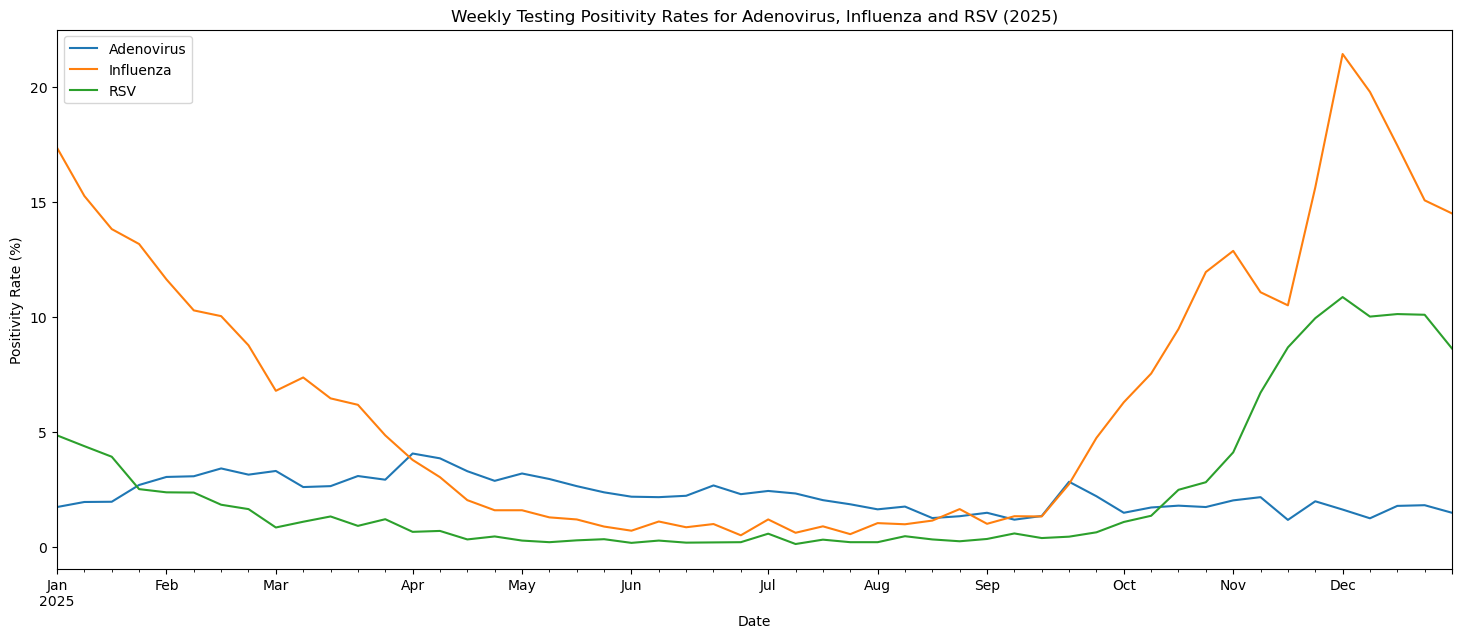

In [20]:
# Line graph
ax=timeseriesdf.plot(figsize=(18,7)) # Figsize is used to make the graph wider and more readable
ax.set_title('Weekly Testing Positivity Rates for Adenovirus, Influenza and RSV (2025)')
ax.set_xlabel('Date')
ax.set_ylabel('Positivity Rate (%)')
plt.show()

In [21]:
# Aggregated data by month
monthly=timeseriesdf.groupby(pd.Grouper(freq='1ME')).mean()

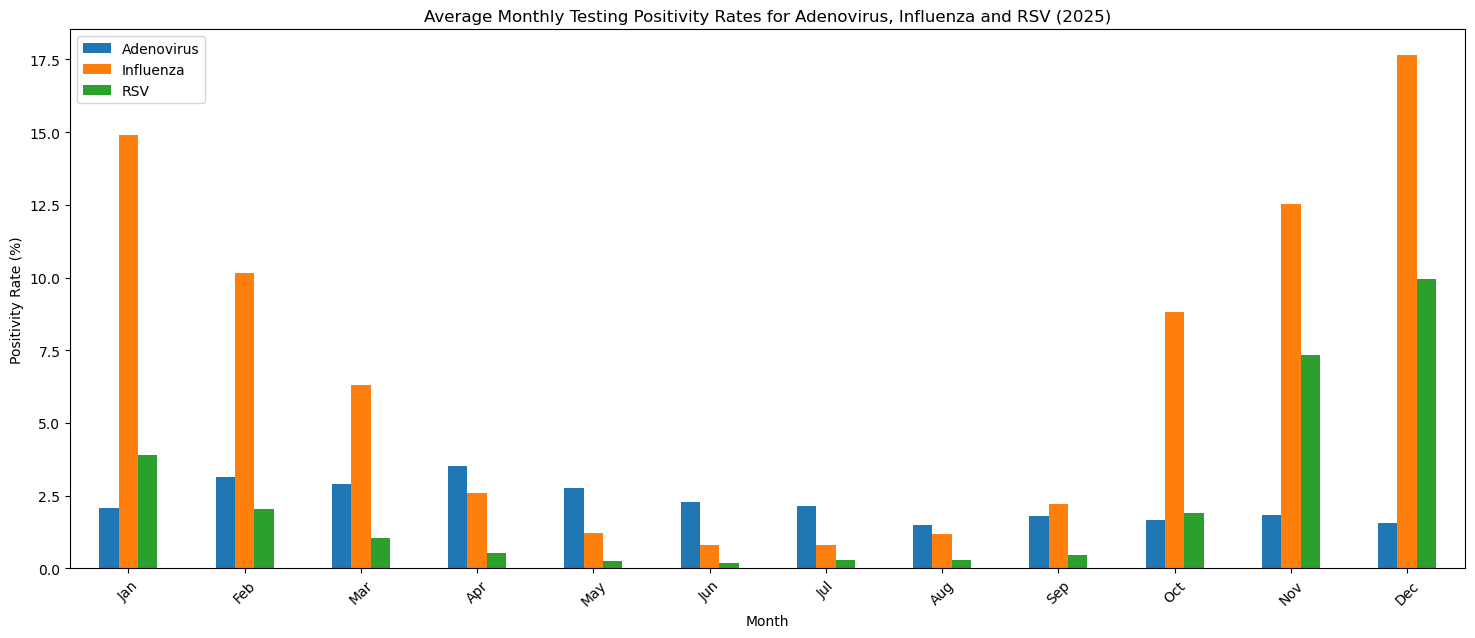

In [22]:
# Bar graph
ax=monthly.plot(kind='bar', figsize=(18,7)) # Figsize is used to make the graph wider and more readable
ax.set_title('Average Monthly Testing Positivity Rates for Adenovirus, Influenza and RSV (2025)')
ax.set_xlabel('Month')
ax.set_ylabel('Positivity Rate (%)')
ax.set_xticklabels(monthly.index.strftime('%b')) # Change x-axis labels as abbreviated month names
plt.xticks(rotation=45) # Rotate labels to prevent overlapping
plt.show()

In [23]:
import ipywidgets as wdg

## Download current data

Click the **Refresh data** button to fetch the latest testing positivity results from the UKHSA API. When you click, a request is sent to the API, the new data is processed, and the charts are updated. The button icon changes to indicate success or failure.

In [24]:
# API access function to return data as a list for the three diseases
def access_api():
    
    # Create API objects for each disease using the global structures
    adenovirus_api=APIwrapper(**structure1)
    influenza_api=APIwrapper(**structure2)
    rsv_api=APIwrapper(**structure3)
    
    # Fetch all data from API for each disease using the global filters
    adenovirus=adenovirus_api.get_all_pages(filters)
    influenza=influenza_api.get_all_pages(filters)
    rsv=rsv_api.get_all_pages(filters)
    
    return [adenovirus, influenza, rsv]

In [25]:
# Button callback function
def api_button_callback(button):
    
    # Try to fetch data from API
    try:
        apidata=access_api()
    # If API call fails, show error on button
    except Exception:
        apibutton.icon="times"
        apibutton.description="Unavailable"
        apibutton.button_style="danger"
        return
    
    # Update the global DataFrame with new data
    global timeseriesdf
    timeseriesdf=wrangle_data(apidata)
    
    # Refresh both graphs with new data
    refresh_graph()
    # Show success icon and reset the button
    apibutton.icon="check"
    apibutton.description="Refresh data"
    apibutton.button_style=""

# Create refresh button
apibutton=wdg.Button(
    description='Refresh data',
    disabled=False,
    button_style='',
    tooltip='Click to download current data from UKHSA API',
    icon='download'
)

# Connect button to callback function
apibutton.on_click(api_button_callback)

display(apibutton)

Button(description='Refresh data', icon='download', style=ButtonStyle(), tooltip='Click to download current da…

## Graphs and Analysis

The dashboard offers two interactive charts to investigate testing positivity trends:

### Weekly Line Chart

Choose one or more diseases from the list and pick the scale (linear or log). To select several diseases at once hold Ctrl (Cmd on Mac) and click. This graph shows the testing positivity rates on a weekly basis and it is possible to compare the circulation patterns throughout the year.

### Monthly Bar Chart

Choose a disease from the list. The chart shows the average testing positivity rates for each month, thus it is easier to see the seasonal patterns.

In [26]:
# Widget for selecting diseases to display
series=wdg.SelectMultiple(
    options=['Adenovirus', 'Influenza', 'RSV'],
    value=['Adenovirus', 'Influenza', 'RSV'],
    rows=3,
    description='Stats:',
    disabled=False
)

# Widget for selecting graph scale
scale=wdg.RadioButtons(
    options=['linear', 'log'],
    description='Scale:',
    disabled=False
)

# Place the widgets side by side
controls=wdg.HBox([series, scale])

# Function to plot the line graph
def timeseries_graph(gcols, gscale):
    if gscale=='linear':
        logscale=False
    else:
        logscale=True
    ncols=len(gcols)
    if ncols>0:
        ax=timeseriesdf[list(gcols)].plot(logy=logscale, figsize=(18,7)) # Figsize is used to make the graph wider and more readable
        ax.set_title('Weekly Testing Positivity Rates for Adenovirus, Influenza and RSV (2025)')
        ax.set_xlabel('Date')
        ax.set_ylabel('Positivity Rate (%)')
        plt.show() # Update the graph
    else:
        print("Click to select data for graph")
        print("(CTRL-Click or CMD-Click on Mac to select more than one category)")

# Capture output in widget output
graph=wdg.interactive_output(timeseries_graph, {'gcols': series, 'gscale': scale})

# Display the line graph
display(controls, graph)

Output()

In [27]:
# Widget for selecting a disease
disease=wdg.Select(
    options=['Adenovirus', 'Influenza', 'RSV'],
    value='Adenovirus',
    rows=3,
    description='Disease:',
    disabled=False
)

# Function to plot the bar graph
def bar_graph(selected_disease):

    # Define color for diseases
    if selected_disease=='Adenovirus':
        bar_colour='tab:blue'
    elif selected_disease=='Influenza':
        bar_colour='tab:orange'
    else:
        bar_colour='tab:green' # For RSV
    
    # Calculate monthly averages
    monthly=timeseriesdf.groupby(pd.Grouper(freq='1ME')).mean()
    ax=monthly[selected_disease].plot(kind='bar', figsize=(18,7), color=bar_colour) # Figsize is used to make the graph wider and more readable
    ax.set_title(f'Average Monthly Testing Positivity Rates for {selected_disease} (2025)')
    ax.set_xlabel('Month')
    ax.set_ylabel('Positivity Rate (%)')
    ax.set_xticklabels(monthly.index.strftime('%b')) # Change x-axis labels as abbreviated month names
    plt.xticks(rotation=45) # Rotate labels to prevent overlapping
    plt.show() # Update the graph

# Capture output in widget output
output=wdg.interactive_output(bar_graph, {'selected_disease': disease})

# Display the bar graph
display(disease, output)

Select(description='Disease:', options=('Adenovirus', 'Influenza', 'RSV'), rows=3, value='Adenovirus')

Output()

In [28]:
# Function to refresh graph after update
def refresh_graph():

    # Refresh line chart
    current=scale.value
    if current==scale.options[0]:
        other=scale.options[1]
    else:
        other=scale.options[0]
    scale.value=other # Force the redraw
    scale.value=current # Change it back
    
    # Refresh bar chart
    current_disease=disease.value
    if current_disease==disease.options[0]:
        other_disease=disease.options[1]
    else:
        other_disease=disease.options[0]
    disease.value=other_disease # Force the redraw
    disease.value=current_disease # Change it back

---
**Dashboard Author:** Yasin Yalcin

**Data Source & License:**
Based on UK Government [data](https://ukhsa-dashboard.data.gov.uk/) published by the [UK Health Security Agency](https://www.gov.uk/government/organisations/uk-health-security-agency).